# Item-based collaborative filtering

Testing whether historical ratings can be used as interpretable inputs for LIME and SHAP.

In [2]:

import pandas as pd
import numpy as np

# Column names for MovieLens 100K ratings
cols = ["user_id", "movie_id", "rating", "timestamp"]
# Load the same training split used by SVD 
train = pd.read_csv(
    "../data/ml-100k/u1.base",
    sep="\t",
    names=cols
)

print("Training ratings:", len(train))

train.head()

Training ratings: 80000


,user_id,movie_id,rating,timestamp
0,1,1,5,874965758
1,1,2,3,876893171
2,1,3,4,878542960
3,1,4,3,876893119
4,1,5,3,889751712


In [3]:

# Put users in rows and movies in cols
user_movie_matrix = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print("rows-cols:", user_movie_matrix.shape)
user_movie_matrix.iloc[:5, :10]


rows-cols: (943, 1650)


movie_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,NaN,4.0,1.0,5.0,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

import ast

# Load the groups 
group_data = pd.read_csv("../results/groups_revised.csv")
# Convert the saved user lists from text back into Python lists
group_data["users"] = group_data["users"].apply(ast.literal_eval)

print("Number of groups:", len(group_data))
print("\nGroups by type:")
print(group_data["group_type"].value_counts())
group_data.head()


Number of groups: 240

Groups by type:
group_type
similar       80
dissimilar    80
random        80
Name: count, dtype: int64


,users,avg_similarity,group_type,group_id,overlap,valid_pairs
0,"[556, 342, 881, 373]",0.249534,similar,1,8.0,6
1,"[296, 265, 869, 721]",0.300932,similar,2,5.0,6
2,"[650, 690, 145, 246]",0.338521,similar,3,6.0,6
3,"[763, 64, 6, 363]",0.324129,similar,4,7.0,6
4,"[251, 831, 327, 901]",0.256486,similar,5,7.0,6


In [5]:

# Calculate similarity between movies using training ratings
movie_pearcor = user_movie_matrix.corr(
    method="pearson",
    min_periods=10
)

print("Movie similarity matrix row, cols:", movie_pearcor.shape)
# Show most similar to Movie 313
movie_pearcor[313].sort_values(ascending=False).head(10)


Movie similarity matrix row, cols: (1650, 1650)


movie_id
313     1.000000
1091    0.737154
905     0.691400
775     0.668153
562     0.661333
1210    0.646230
201     0.644826
915     0.632268
796     0.630656
1267    0.627089
Name: 313, dtype: float64

In [6]:

def item_predict(user_history, movie_id, k=20):

    # Get movie_sim between the target movie and all movies
    movie_sim = movie_pearcor[movie_id]

    # Add similarity values to the user's historical ratings
    history = user_history.copy()
    history["similarity"] = history["movie_id"].map(movie_sim)

    # Keep only positively correlated movies
    history = history[history["similarity"] > 0]

    # Select the k most similar movies
    neigh_movies = history.nlargest(k, "similarity")

    # Handle users with no valid neigh_movies
    if neigh_movies.empty:
        return user_history["rating"].mean()

    # Calculate the similarity-weighted predicted rating
    prediction = np.average(
        neigh_movies["rating"],
        weights=neigh_movies["similarity"]
    )

    return prediction


# Test
user_id = 556
movie_id = 313
user_history = train[train["user_id"] == user_id]
prediction = item_predict(user_history, movie_id)

print("user:", user_id)
print("movie:", movie_id)
print("prediction of knn:", prediction)


user: 556
movie: 313
prediction of knn: 4.479985929946514


In [ ]:

# Find which historical movies contribute to the prediction
history = user_history.copy()
# Add similarity values to the user's historical ratings
# history["movie_id"].map(movie_pearcor[movie_id]) we use the map function to map the movie_id to its corresponding similarity values from the movie_pearcor matrix. 
# This allows us to see how similar each historical movie is to the target movie (movie_id) for the given user.
history["similarity"] = history["movie_id"].map(movie_pearcor[movie_id])

# Select the 20 most similar movies used by our KNN
neigh_movies = history[history["similarity"] > 0].nlargest(20, "similarity")

# Pick the most similar historical movie
rating_to_remove = neigh_movies.iloc[0]

# Remove it from a copy of the user's history
modified_history = user_history.drop(index=rating_to_remove.name)

# Predict again WITHOUT retraining
new_pred = item_predict(modified_history, movie_id)

print("removed movie:", rating_to_remove["movie_id"])
print("historical rating:", rating_to_remove["rating"])
print("og prediction:", prediction)
print("mod prediction:", new_pred)
print("Diff:", new_pred - prediction)


removed movie: 481.0
historical rating: 5.0
og prediction: 4.479985929946514
mod prediction: 4.346245666839444
Diff: -0.13374026310706988


In [8]:

# Predict twice with exactly the same inputs
pred_1 = item_predict(user_history, movie_id)
pred_2 = item_predict(user_history, movie_id)

# Find a movie outside the 20 selected neigh_movies
not_used_rs = user_history[
    ~user_history["movie_id"].isin(neigh_movies["movie_id"])
]

# Remove one unused historical rating
not_used_r = not_used_rs.iloc[0]
unused_history = user_history.drop(index=not_used_r.name)

# Predict again
unused_prediction = item_predict(unused_history, movie_id)

print("First prediction:", pred_1)
print("Second prediction:", pred_2)
print("Same result:", pred_1 == pred_2)
print("Unused movie removed:", not_used_r["movie_id"])
print("Change after removing unused movie:", unused_prediction - pred_1)


First prediction: 4.479985929946514
Second prediction: 4.479985929946514
Same result: True
Unused movie removed: 127
Change after removing unused movie: 0.0


In [11]:

# Load the same test split used for SVD
test = pd.read_csv(
    "../data/ml-100k/u1.test",
    sep="\t",
    names=cols
)

# Keep only movies that appeared in training
test_known = test[
    test["movie_id"].isin(user_movie_matrix.columns)
].copy()

print("Og test ratings:", len(test))
print("Ratings to evaluate:", len(test_known))
print("removed ratings:", len(test) - len(test_known))


Og test ratings: 20000
Ratings to evaluate: 19968
removed ratings: 32


In [ ]:

# Store each user's training ratings for easy access
user_histories = {
    user: history
    for user, history in train.groupby("user_id")
}

# Generate predictions for the test ratings
predictions = []

for row in test_known.itertuples(index=False):
    history = user_histories[row.user_id]
    predicted_rating = item_predict(history,row.movie_id)
    predictions.append(predicted_rating)

# Calculate RMSE between actual and predicted ratings
actual_ratings = test_known["rating"].to_numpy()

knn_rmse = np.sqrt(
    np.mean((actual_ratings - np.array(predictions)) ** 2)
)

print("svd rmse: 0.9557")
print("knn rmse:", round(knn_rmse, 4))
print("evaluated predictions:", len(predictions))


svd rmse: 0.9557
knn rmse: 1.0604
evaluated predictions: 19968


In [20]:

# Calculate each user's average training rating
user_means = train.groupby("user_id")["rating"].mean()

# Predict each test rating using only that user's average
bl_pred = test_known["user_id"].map(user_means).to_numpy()

# Calculate the baseline RMSE
bl_rmse = np.sqrt(np.mean((actual_ratings - bl_pred) ** 2))

print("avg user baseline rmse:", round(bl_rmse, 4))
print("knn rmse:", round(knn_rmse, 4))
print("svd rmse: 0.9557")


avg user baseline rmse: 1.0628
knn rmse: 1.0604
svd rmse: 0.9557


In [22]:

# Select 5 historical movies from our KNN neigh_movies
feature_movies = neigh_movies.head(5)["movie_id"].astype(int).tolist()

# Retrieve the user's ratings for those movies
feature_ratings = user_history[user_history["movie_id"].isin(feature_movies)]

print("Movies to perturb:")
print(feature_movies)
print("historical ratings of those movies:")
print(feature_ratings[["movie_id", "rating"]])


Movies to perturb:
[481, 64, 496, 604, 173]
historical ratings of those movies:
       movie_id  rating
42704        64       5
42712       173       3
42733       481       5
42736       496       5
42742       604       5


In [ ]:

# Predict using a binary mask for the five selected movies
def mask_pred(mask):

    # Start with the complete historical rating data
    masked_history = user_history.copy()

    # Check each of the five explanation features 
    for movie, keep in zip(feature_movies, mask):

        # If the mask contains 0, remove that movie's rating
        if keep == 0:
            masked_history = masked_history[
                masked_history["movie_id"] != movie
            ]

    # Predict using the remaining historical ratings
    return item_predict(masked_history, movie_id)


# Test with all five ratings included
og_prediction = mask_pred([1, 1, 1, 1, 1])
# Test with Movie 481 removed
first_removed = mask_pred([0, 1, 1, 1, 1])

print("all five included:", og_prediction)
print("movie 481 removed:", first_removed)
print("diff:", first_removed - og_prediction)


all five included: 4.479985929946514
movie 481 removed: 4.346245666839444
diff: -0.13374026310706988


In [25]:

# Predict ratings for multiple binary masks
def masks_pred(masks):

    # Convert the masks into a NumPy array
    masks = np.atleast_2d(masks)

    # Store a prediction for each mask
    predictions = []

    for mask in masks:
        prediction = mask_pred(mask)
        predictions.append(prediction)

    return np.array(predictions)


# Test three different combinations
t_masks = [
    [1, 1, 1, 1, 1],  # Keep all five ratings
    [0, 1, 1, 1, 1],  # Remove Movie 481
    [0, 0, 0, 0, 0]   # Remove all five selected ratings
]

# Get all three predictions
t_pred = masks_pred(t_masks)

for mask, result in zip(t_masks, t_pred):
    print(mask, "->", result)


[1, 1, 1, 1, 1] -> 4.479985929946514
[0, 1, 1, 1, 1] -> 4.346245666839444
[0, 0, 0, 0, 0] -> 4.1715750077464016


## SHAP and LIME explanations

In [15]:

%pip install shap lime

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import shap
import lime

print("SHAP version:", shap.__version__)

SHAP version: 0.49.1


Baseline prediction: 4.1715750077464016
Og prediction: 4.479985929946514


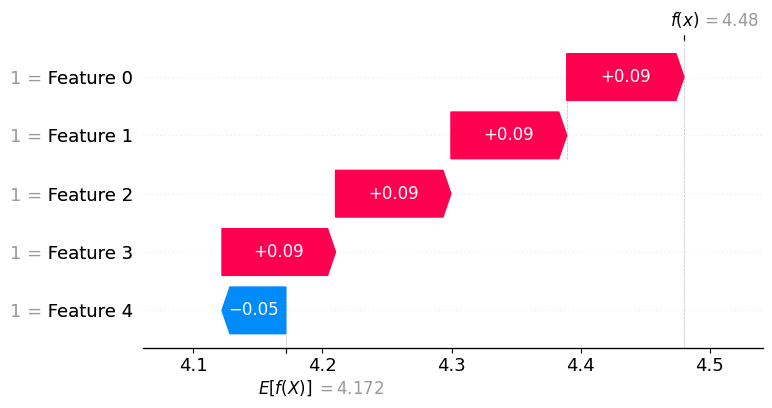

In [29]:

# Define the baseline: all five selected ratings are removed
base = np.zeros((1, 5))

# Create the SHAP explainer
#shap.Explainer can take a model and a baseline dataset to explain predictions. 
explainer = shap.Explainer(masks_pred, base, algorithm="exact")

# Explain the original prediction
shap_val = explainer(np.ones((1, 5)))

# Display the explanation
print("Baseline prediction:", shap_val.base_values[0])
print("Og prediction:", masks_pred(np.ones((1, 5)))[0])

shap.plots.waterfall(shap_val[0])



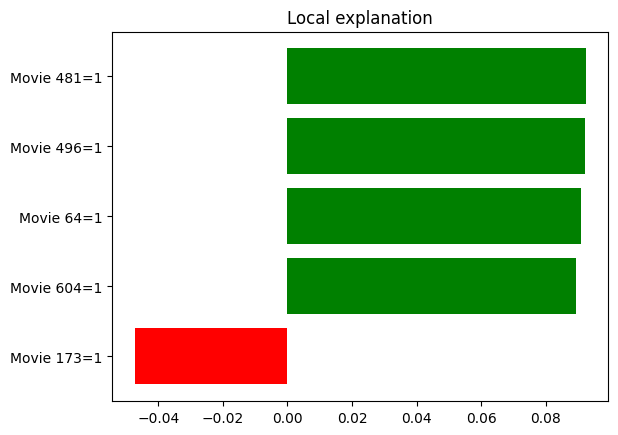

In [ ]:

from lime.lime_tabular import LimeTabularExplainer
from itertools import product

# All 32 possible combinations of our 5 switches
masks = np.array(list(product([0, 1], repeat=5)))

# Set up LIME
lime_explainer = LimeTabularExplainer(
    masks,
    feature_names=[f"Movie {m}" for m in feature_movies],
    categorical_features=list(range(5)),
    mode="regression",
    random_state=42
)

# Generate a LIME explanation
# lime_explainer.explain_instance can be used to explain a single instance by generating perturbed samples and fitting a local surrogate model.
lime_res = lime_explainer.explain_instance(
    np.ones(5), masks_pred, num_features=5
)

lime_res.as_pyplot_figure();


In [31]:
#lime local fidely score 
lime_res.score

0.9277468353884313

LIME explains approximately 92.8% of the variation in the predictions it sampled, under its local weighting scheme.

In [32]:

# Generate the same LIME explanation 3 times
results = []

for run in range(3):
    
    explanation = lime_explainer.explain_instance(
        np.ones(5),
        masks_pred,
        num_features=5,
        num_samples=500
    )

    results.append(dict(explanation.as_list()))

# Compare the explanations
pd.DataFrame(results).round(4)


,Movie 604=1,Movie 64=1,Movie 496=1,Movie 481=1,Movie 173=1
0,0.0930,0.0913,0.0904,0.0894,-0.0505
1,0.0929,0.0900,0.0911,0.0950,-0.0475
2,0.0886,0.0884,0.0947,0.0906,-0.0452


In [33]:
#Stability of LIME explanations can be assessed by running the explanation multiple times and comparing the results. 
#The standard deviation of the feature weights across runs can provide insight into the variability of the explanations.
pd.DataFrame(results).std().round(4)

Movie 604=1    0.0025
Movie 64=1     0.0015
Movie 496=1    0.0023
Movie 481=1    0.0030
Movie 173=1    0.0027
dtype: float64

In [34]:
#Complexity of the LIME explanation can be measured by counting the number of features included in the explanation. 
len(lime_res.as_list())


5

## Group Recommendation Experiments

In [40]:

# Select our first group
group_users = group_data.iloc[0]["users"]

# Predict Movie 313 for each group member
group_pred = []

for user in group_users:
    rating = item_predict(user_histories[user], 313)
    group_pred.append(rating)

# Calculate the two group scores
avg_score = np.mean(group_pred)
lm_score = np.min(group_pred)

pd.DataFrame({
    "User": group_users,
    "Predicted rating": group_pred
})


,User,Predicted rating
0,556,4.479986
1,342,3.153033
2,881,3.342797
3,373,3.505397


In [41]:

pd.Series({
    "Average": avg_score,
    "Least Misery": lm_score
})


Average         3.620303
Least Misery    3.153033
dtype: float64

In [ ]:

# Copy the group's original predictions
changed_pred = group_pred.copy()
# Change User 556's prediction by masking Movie 481
changed_pred[0] = mask_pred([0, 1, 1, 1, 1])

# Compare group scores
pd.DataFrame({
    "Original": [avg_score, lm_score],
    "Modified": [np.mean(changed_pred), np.min(changed_pred)]
}, index=["Average", "Least Misery"])


,Original,Modified
Average,3.620303,3.586868
Least Misery,3.153033,3.153033


Small test to investigate user 342 
Find user 342 most similar historical movies

In [43]:

user_id = 342
movie_id = 313

history = user_histories[user_id].copy()
history["similarity"] = history["movie_id"].map(movie_pearcor[movie_id])
neigh_movies_342 = history[history["similarity"] > 0].nlargest(20, "similarity")
neigh_movies_342[["movie_id", "rating", "similarity"]].head()


,movie_id,rating,similarity
20510,716,2,0.589506
20503,547,5,0.535497
20513,756,3,0.466445
20438,149,5,0.408248
20422,57,3,0.407117


In [ ]:

# Select the most similar historical movie
movie_to_remove = int(neigh_movies_342.iloc[0]["movie_id"])

# Remove it from User 342's history
modified_history = user_histories[342][
    user_histories[342]["movie_id"] != movie_to_remove
]

# Recalculate User 342's prediction
new_pred = item_predict(modified_history, 313)
# Original predictions for our four users
group_users = [556, 342, 881, 373]

og_pred = [
    item_predict(user_histories[user], 313)
    for user in group_users
]

# Replace only User 342's prediction
new_preds = og_pred.copy()
new_preds[1] = new_pred

# Compare both group scores
print("Movie removed:", movie_to_remove)

pd.DataFrame({
    "Original": [
        np.mean(og_pred),
        np.min(og_pred)
    ],
    "Modified": [
        np.mean(new_preds),
        np.min(new_preds)
    ]
}, index=["Average", "Least Misery"])


Movie removed: 716


,Original,Modified
Average,3.620303,3.651565
Least Misery,3.153033,3.278080


In [47]:
#choose_movies gets the top n most similar movies to a given movie_id for a specific user_id based on their historical ratings. 
def chose_movies(user_id, movie_id, n=5):

    history = user_histories[user_id].copy()
    history["similarity"] = history["movie_id"].map(movie_pearcor[movie_id])
    neigh_movies = history[
        (history["similarity"] > 0) &
        (history["movie_id"] != movie_id)
    ]

    top_movies = neigh_movies.nlargest(n, "similarity")

    return top_movies["movie_id"].astype(int).tolist()


# Test function
features = chose_movies(556, 313)

print(features)

[481, 64, 496, 604, 173]


In [49]:
def pred_masked(user_id, movie_id, features, mask):

    history = user_histories[user_id].copy()

    for movie, keep in zip(features, mask):

        if keep == 0:
            history = history[
                history["movie_id"] != movie
            ]

    return item_predict(history, movie_id)

In [ ]:
original = pred_masked(556, 313, features, [1, 1, 1, 1, 1])
removed = pred_masked(556, 313, features, [0, 0, 0, 0, 0])

print("Original:", original)
print("All five removed:", removed)

Original: 4.479985929946514
All five removed: 4.1715750077464016


Create a prediction function for whichever user 

In [53]:
def create_pred(user_id, movie_id, features):

    def masks_pred(masks):
        masks = np.atleast_2d(masks)

        return np.array([
            pred_masked(user_id, movie_id, features, mask)
            for mask in masks
        ])

    return masks_pred

In [ ]:
features = chose_movies(556, 313)
predict_fn = create_pred(556, 313, features)

t_masks = [
    [1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0]
]

print(predict_fn(t_masks))

[4.47998593 4.17157501]


In [57]:
#exp_one function generates explanations for a specific user's predicted rating for a movie using both LIME and SHAP methods.
#it selects the top n historical movies that contribute to the prediction, creates a prediction function based on these features, and then generates explanations using both LIME and SHAP. The results include the selected features and the explanations from both methods.
def exp_one(user_id, movie_id, n=5):

    features = chose_movies(user_id, movie_id, n)

    if len(features) != n:
        return None

    predict_fn = create_pred(user_id, movie_id, features)
    # All possible binary masks
    masks = np.array(list(product([0, 1], repeat=n)))
    # LIME
    lime_explainer = LimeTabularExplainer(
        masks,
        feature_names=[f"Movie {m}" for m in features],
        categorical_features=list(range(n)),
        mode="regression",
        random_state=42
    )

    lime_res = lime_explainer.explain_instance(
        np.ones(n),
        predict_fn,
        num_features=n,
        num_samples=500
    )

    # SHAP
    base = np.zeros((1, n))
    shap_explainer = shap.Explainer(
        predict_fn, base, algorithm="exact"
    )

    shap_res = shap_explainer(np.ones((1, n)))

    return {
        "features": features,
        "lime": lime_res,
        "shap": shap_res
    }

In [58]:
result = exp_one(556, 313)

print("features:", result["features"])
print("LIME R^2:", result["lime"].score)
print("LIME weights:", result["lime"].as_list())
print("SHAP values:", result["shap"].values[0])

features: [481, 64, 496, 604, 173]
LIME R^2: 0.9226549421873871
LIME weights: [('Movie 481=1', 0.09086041445168767), ('Movie 64=1', 0.09052920327992593), ('Movie 496=1', 0.08985725378835215), ('Movie 604=1', 0.08604123823809628), ('Movie 173=1', -0.045270770697131174)]
SHAP values: [ 0.09081384  0.08965156  0.08938409  0.08794093 -0.0493795 ]


In [59]:
# Generate all 32 possible masks
masks = np.array(list(product([0, 1], repeat=5)))

# Actual KNN predictions for each mask
predict_fn = create_pred(556, 313, result["features"])
actual = predict_fn(masks)

# LIME's additive approximation
lime_weights = np.zeros(5)

for feature, weight in result["lime"].local_exp[1]:
    lime_weights[feature] = weight
#intercept is the predicted value when all features are set to zero 
lime_predictions = (
    result["lime"].intercept[1] + masks @ lime_weights
)

# SHAP's additive approximation
shap_predictions = (
    result["shap"].base_values[0] + masks @ result["shap"].values[0]
)

# Compare both methods
lime_mae = np.mean(np.abs(actual - lime_predictions))
shap_mae = np.mean(np.abs(actual - shap_predictions))

print("LIME MAE:", lime_mae)
print("SHAP MAE:", shap_mae)

LIME MAE: 0.023795727777322334
SHAP MAE: 0.027796364319348704


In [60]:
# Original prediction with all ratings present
original = predict_fn([1, 1, 1, 1, 1])[0]

# Actual prediction changes
actual_changes = original - actual

# Changes estimated by LIME
lime_changes = (1 - masks) @ lime_weights

# Changes estimated by SHAP
shap_changes = (1 - masks) @ result["shap"].values[0]

# Compare errors
lime_fidelity = np.mean(np.abs(actual_changes - lime_changes))

shap_fidelity = np.mean(np.abs(actual_changes - shap_changes))

print("LIME fidelity error:", lime_fidelity)
print("SHAP fidelity error:", shap_fidelity)

LIME fidelity error: 0.02712016115794514
SHAP fidelity error: 0.02779636431934855


Select groups, get a movie that noone has rated in training, check every member has 5 similar ratings avaialble for explanation, record all 4 users.

In [63]:
rng = np.random.default_rng(42)
cases = []

for group_type in ["similar", "dissimilar", "random"]:

    groups = group_data[
        group_data["group_type"] == group_type
    ].sample(frac=1, random_state=42)

    selected = 0

    for _, group in groups.iterrows():

        users = group["users"]

        rated = set()

        for user in users:
            rated.update(user_histories[user]["movie_id"])

        for movie in rng.permutation(movie_pearcor.columns):

            movie = int(movie)

            if movie in rated:
                continue

            if all(len(chose_movies(user, movie)) == 5
                   for user in users):

                for user in users:
                    cases.append({
                        "group_type": group_type,
                        "group_id": group["group_id"],
                        "user_id": user,
                        "movie_id": movie
                    })

                selected += 1
                break

        if selected == 80:
            break

cases = pd.DataFrame(cases)

print(cases)
print("\nCases per category:")
print(cases["group_type"].value_counts())

    group_type  group_id  user_id  movie_id
0      similar        31      534       521
1      similar        31      102       521
2      similar        31       84       521
3      similar        31      907       521
4      similar         1      556       922
..         ...       ...      ...       ...
955     random       175      712       629
956     random       212      193       520
957     random       212      867       520
958     random       212      214       520
959     random       212      887       520

[960 rows x 4 columns]

Cases per category:
group_type
similar       320
dissimilar    320
random        320
Name: count, dtype: int64


In [ ]:
masks = np.array(list(product([0, 1], repeat=5)))

records = []

for case in cases.itertuples(index=False):

    user = int(case.user_id)
    movie = int(case.movie_id)
    # Generate both explanations
    result = exp_one(user, movie)

    if result is None:
        raise ValueError(f"Missing features: User {user}, Movie {movie}")

    # Get actual predictions for all 32 masks
    predict_fn = create_pred(user, movie, result["features"])
    actual = predict_fn(masks)

    # Extract LIME weights
    lime_weights = np.zeros(5)

    for feature, weight in result["lime"].local_exp[1]:
        lime_weights[feature] = weight

    # Extract SHAP weights
    shap_weights = result["shap"].values[0]

    # Actual changes when ratings are removed
    actual_changes = actual[-1] - actual

    # Changes estimated by the explanations
    lime_changes = (1 - masks) @ lime_weights
    shap_changes = (1 - masks) @ shap_weights

    # Fidelity errors
    lime_mae = np.mean(np.abs(actual_changes - lime_changes))
    shap_mae = np.mean(np.abs(actual_changes - shap_changes))

    # Save this case's results
    records.append({
        "group_type": case.group_type,
        "group_id": case.group_id,
        "user_id": user,
        "movie_id": movie,
        "lime_mae": lime_mae,
        "shap_mae": shap_mae,
        "lime_r2": result["lime"].score
    })

# Create results table
small_test = pd.DataFrame(records)

print("Completed cases:", len(small_test))
print(small_test.round(4))

KeyboardInterrupt: 

In [ ]:
print(small_test.groupby("group_type")[["lime_mae", "shap_mae", "lime_r2"]].mean().round(4))

            lime_mae  shap_mae  lime_r2
group_type                             
dissimilar    0.0332    0.0432   0.9396
random        0.0522    0.0761   0.9211
similar       0.0354    0.0445   0.9290


In [ ]:
def get_lime_weig(user_id, movie_id, seed):

    features = chose_movies(user_id, movie_id)
    predict_fn = create_pred(user_id, movie_id, features)
    masks = np.array(list(product([0, 1], repeat=5)))

    explainer = LimeTabularExplainer(
        masks,
        feature_names=[f"Movie {m}" for m in features],
        categorical_features=list(range(5)),
        mode="regression",
        random_state=seed
    )

    explanation = explainer.explain_instance(
        np.ones(5),
        predict_fn,
        num_features=5,
        num_samples=500
    )

    weights = np.zeros(5)

    for index, weight in explanation.local_exp[1]:
        weights[index] = weight

    return weights

In [ ]:
stability_records = []

for case in cases.itertuples(index=False):

    runs = []

    for seed in [42, 43, 44, 45, 46]:
        weights = get_lime_weig(
            int(case.user_id),
            int(case.movie_id),
            seed
        )
        runs.append(weights)

    runs = np.array(runs)
    stability = runs.std(axis=0, ddof=1).mean()

    stability_records.append({
        "group_type": case.group_type,
        "group_id": case.group_id,
        "user_id": case.user_id,
        "movie_id": case.movie_id,
        "lime_stability_sd": stability
    })

stability_results = pd.DataFrame(stability_records)

print(stability_results.round(5))

KeyboardInterrupt: 

In [66]:
import time

def calc_cost(user_id, movie_id):

    features = chose_movies(user_id, movie_id)
    predict_fn = create_pred(user_id, movie_id, features)
    cnt = [0]

    def cnt_preds(masks):
        masks = np.atleast_2d(masks)
        cnt[0] += len(masks)
        return predict_fn(masks)

    masks = np.array(list(product([0, 1], repeat=5)))

    # Measure LIME
    start = time.perf_counter()

    lime_explainer = LimeTabularExplainer(
        masks,
        feature_names=[f"Movie {m}" for m in features],
        categorical_features=list(range(5)),
        mode="regression",
        random_state=42
    )

    lime_explainer.explain_instance(
        np.ones(5),
        cnt_preds,
        num_features=5,
        num_samples=500
    )

    lime_time = time.perf_counter() - start
    lime_calls = cnt[0]
    # Reset counter for SHAP
    cnt[0] = 0

    # Measure SHAP
    start = time.perf_counter()

    shap_explainer = shap.Explainer(
        cnt_preds,
        np.zeros((1, 5)),
        algorithm="exact"
    )

    shap_explainer(np.ones((1, 5)))
    shap_time = time.perf_counter() - start
    shap_calls = cnt[0]

    return {
        "lime_time": lime_time,
        "shap_time": shap_time,
        "lime_evaluations": lime_calls,
        "shap_evaluations": shap_calls
    }

In [67]:
calc_cost(556, 313)

{'lime_time': 0.7453266999218613,
 'shap_time': 0.05149670003447682,
 'lime_evaluations': 500,
 'shap_evaluations': 32}

In [ ]:
cost_records = []

for case in cases.itertuples(index=False):

    calculations = calc_cost(
        int(case.user_id),
        int(case.movie_id)
    )

    cost_records.append({
        "group_type": case.group_type,
        "group_id": case.group_id,
        "user_id": case.user_id,
        "movie_id": case.movie_id,
        **calculations
    })

cost_results = pd.DataFrame(cost_records)

print(cost_results.groupby("group_type")[
    ["lime_time", "shap_time",
     "lime_evaluations", "shap_evaluations"]
].mean().round(4))

KeyboardInterrupt: 

In [ ]:
activity = []

for (group_type, group_id), group in cases.groupby(
    ["group_type", "group_id"]
):
    users = group["user_id"].astype(int).tolist()
    movie = int(group["movie_id"].iloc[0])

    original = np.array([
        item_predict(user_histories[u], movie)
        for u in users
    ])

    original_lm = original.min()
    changes = 0
    tot = 0

    for i, user in enumerate(users):
        features = chose_movies(user, movie)
        predict_fn = create_pred(user, movie, features)

        new_user_scores = predict_fn(masks)
        other_min = np.delete(original, i).min()
        new_lm = np.minimum(new_user_scores, other_min)
        changes += np.sum(
            np.abs(new_lm - original_lm) > 1e-9
        )

        tot += len(masks)

    activity.append({
        "group_type": group_type,
        "group_id": group_id,
        "lm_change_rate": changes / tot
    })

activity = pd.DataFrame(activity)

print(activity.round(4))

   group_type  group_id  lm_change_rate
0  dissimilar        81          0.2422
1  dissimilar       111          0.2734
2      random       161          0.2422
3      random       191          0.2891
4     similar         1          0.3906
5     similar        31          0.2422


In [72]:
masks = np.array(list(product([0, 1], repeat=5)))

records = []

for (group_type, group_id), group in cases.groupby(
    ["group_type", "group_id"]
):
    users = group["user_id"].astype(int).tolist()
    movie = int(group["movie_id"].iloc[0])

    original = np.array([
        item_predict(user_histories[u], movie)
        for u in users
    ])

    original_lm = original.min()

    for i, user in enumerate(users):

        result = exp_one(user, movie)
        predict_fn = create_pred(
            user, movie, result["features"]
        )

        actual_user = predict_fn(masks)
        # Other three members stay unchanged
        other_min = np.delete(original, i).min()
        actual_lm = np.minimum(actual_user, other_min)
        # Which masks really changed Least Misery?
        active = np.abs(actual_lm - original_lm) > 1e-9
        lime_weights = np.zeros(5)

        for index, weight in result["lime"].local_exp[1]:
            lime_weights[index] = weight

        weights = {
            "LIME": lime_weights,
            "SHAP": result["shap"].values[0]
        }

        for method, importance in weights.items():

            estimated_user = (
                original[i] - (1 - masks) @ importance
            )

            estimated_lm = np.minimum(
                estimated_user, other_min
            )

            errors = np.abs(actual_lm - estimated_lm)

            for j in range(len(masks)):
                records.append({
                    "group_type": group_type,
                    "group_id": group_id,
                    "method": method,
                    "active": bool(active[j]),
                    "error": float(errors[j])
                })

lm_errors = pd.DataFrame(records)


KeyboardInterrupt: 

In [ ]:

# Load completed group experiment 
group_results = pd.read_csv("../results/full_group_fidelity.csv")

# Select Least Misery results
lm_results = group_results[
    group_results["aggregation"] == "Least Misery"
]

# stability of group scores and explanation errors
print(lm_results.groupby(["group_type", "method"])[
    ["active_mae", "change_rate"]
].mean().round(4))

                   active_mae  change_rate
group_type method                         
dissimilar LIME        0.0355       0.2691
           SHAP        0.0389       0.2691
random     LIME        0.0585       0.2688
           SHAP        0.0788       0.2688
similar    LIME        0.0338       0.2713
           SHAP        0.0410       0.2713


Changed the selected groups from 2 to 80 and now we check it, previous cells were with only 2 groups of each category

In [76]:
print("total cases:", len(cases))
print(cases.groupby("group_type").agg(groups=("group_id", "nunique"),individuals=("user_id", "count")))

total cases: 960
            groups  individuals
group_type                     
dissimilar      80          320
random          80          320
similar         80          320


In [ ]:
cases.to_csv("../results/full_cases.csv",index=False)

In [ ]:
masks = np.array(list(product([0, 1], repeat=5)))

full_records = []

for number, case in enumerate(cases.itertuples(index=False), start=1):

    user = int(case.user_id)
    movie = int(case.movie_id)
    result = exp_one(user, movie)

    if result is None:
        raise ValueError(f"Missing features: {user}, {movie}")

    predict_fn = create_pred(user, movie, result["features"])
    #f(z) real knn prediction for each mask z
    actual = predict_fn(masks)

    # LIME weights
    lime_weights = np.zeros(5)

    for index, weight in result["lime"].local_exp[1]:
        lime_weights[index] = weight

    # SHAP weights
    shap_weights = result["shap"].values[0]

    # Actual changes and estimated changes
    #actual[-1] is the prediction when all five selected ratings are retained, and actual is the array of predictions for all 32 masks. 
    # The difference gives the actual change in prediction when each rating is removed.
    actual_changes = actual[-1] - actual

    #How much LIME estimates the prediction changes
    lime_changes = (1 - masks) @ lime_weights
    #How much SHAP's weights estimate it changes
    shap_changes = (1 - masks) @ shap_weights

    full_records.append({
        "group_type": case.group_type,
        "group_id": case.group_id,
        "user_id": user,
        "movie_id": movie,
        "lime_mae": np.mean(np.abs(actual_changes - lime_changes)),
        "shap_mae": np.mean(np.abs(actual_changes - shap_changes)),
        "lime_r2": result["lime"].score
    })

    # Save progress every 40 cases
    if number % 40 == 0:
        pd.DataFrame(full_records).to_csv(
            "../results/full_individual_fidelity.csv",
            index=False
        )
        print(f"Completed {number} / {len(cases)} cases", flush=True)

full_fidelity = pd.DataFrame(full_records)

full_fidelity.to_csv(
    "../results/full_individual_fidelity.csv",
    index=False
)

print("tot completed:", len(full_fidelity))

Completed 40 / 960 cases
Completed 80 / 960 cases
Completed 120 / 960 cases
Completed 160 / 960 cases
Completed 200 / 960 cases
Completed 240 / 960 cases
Completed 280 / 960 cases
Completed 320 / 960 cases
Completed 360 / 960 cases
Completed 400 / 960 cases
Completed 440 / 960 cases
Completed 480 / 960 cases
Completed 520 / 960 cases
Completed 560 / 960 cases
Completed 600 / 960 cases
Completed 640 / 960 cases
Completed 680 / 960 cases
Completed 720 / 960 cases
Completed 760 / 960 cases
Completed 800 / 960 cases
Completed 840 / 960 cases
Completed 880 / 960 cases
Completed 920 / 960 cases
Completed 960 / 960 cases
Total completed: 960


In [81]:
# Load the completed experiment
full_fidelity = pd.read_csv("../results/full_individual_fidelity.csv")

print("Completed cases:", len(full_fidelity))
print(full_fidelity.groupby("group_type")[["lime_mae", "shap_mae", "lime_r2"]].mean().round(4)
)

Completed cases: 960
            lime_mae  shap_mae  lime_r2
group_type                             
dissimilar    0.0332    0.0432   0.9396
random        0.0522    0.0761   0.9211
similar       0.0354    0.0445   0.9290


Fixing a mistake of re writing everything.

In [ ]:
full_fidelity.to_csv(
    "../results/full_individual_fidelity_backup.csv",
    index=False
)

In [84]:
grp_means = full_fidelity.groupby(["group_type", "group_id"],as_index=False)[["lime_mae", "shap_mae"]].mean()
grp_means["difference"] = (grp_means["shap_mae"] - grp_means["lime_mae"])

print(grp_means.groupby("group_type")[["lime_mae", "shap_mae", "difference"]].agg(["mean", "std"]).round(4))

           lime_mae         shap_mae         difference        
               mean     std     mean     std       mean     std
group_type                                                     
dissimilar   0.0332  0.0214   0.0432  0.0429     0.0100  0.0236
random       0.0522  0.0301   0.0761  0.0624     0.0239  0.0370
similar      0.0354  0.0271   0.0445  0.0488     0.0091  0.0255


In [86]:
grp_means["winner"] = np.where(
    grp_means["lime_mae"] < grp_means["shap_mae"],
    "LIME",
    np.where(grp_means["shap_mae"] < grp_means["lime_mae"],"SHAP","Tie"))

print(pd.crosstab(grp_means["group_type"], grp_means["winner"]))
grp_means.to_csv(
    "../results/full_group_mean_individual_fidelity.csv",
    index=False
)

winner      LIME  SHAP
group_type            
dissimilar    53    27
random        62    18
similar       54    26


In [ ]:
from pathlib import Path

full_cases = pd.read_csv("../results/full_cases.csv")
output = Path("../results/full_group_fidelity.csv")
masks = np.array(list(product([0, 1], repeat=5)))

# Check which groups have already been completed
completed = set()
#if output file exists, read and get the completed group_type and group_id pairs
if output.exists():
    saved = pd.read_csv(output)
    completed = set(zip(saved["group_type"], saved["group_id"]))
#for each group in full_cases, calculate the fidelity of LIME and SHAP explanations for the group's predictions.
# The code skips groups that have already been completed and keeps track of the number of completed groups.
for (group_type, group_id), group in full_cases.groupby(
    ["group_type", "group_id"]
):

    if (group_type, group_id) in completed:
        continue
    #users in the group and the movie being predicted are extracted.
    #The original predictions for each user in the group are calculated using the KNN model.
    users = group["user_id"].astype(int).tolist()
    movie = int(group["movie_id"].iloc[0])

    original = np.array([
        item_predict(user_histories[u], movie)
        for u in users
    ])

    errors = {}
    active_errors = {}
    change_counts = {"Average": 0, "Least Misery": 0}
    #for each explanation method (LIME and SHAP) and aggregation method (Average and Least Misery), empty lists are initialized to store the errors and active errors.
    for method in ["LIME", "SHAP"]:
        for aggregation in ["Average", "Least Misery"]:
            errors[(method, aggregation)] = []
            active_errors[(method, aggregation)] = []
    #for each user in the group, the code generates explanations using both LIME and SHAP methods. 
    # It then calculates the actual predictions for all possible binary masks of the selected features.
    #  The code computes the estimated predictions based on the explanations and compares them to the actual predictions to calculate errors.
    #  It also tracks how many times the group's prediction changes when a user's prediction is modified.
    for i, user in enumerate(users):

        result = exp_one(user, movie)
        predict_fn = create_pred(user, movie, result["features"])

        actual_user = predict_fn(masks)

        lime_weights = np.zeros(5)

        for index, weight in result["lime"].local_exp[1]:
            lime_weights[index] = weight

        weights = {
            "LIME": lime_weights,
            "SHAP": result["shap"].values[0]
        }

        for aggregation in ["Average", "Least Misery"]:

            if aggregation == "Average":
                actual_group = (
                    original.sum() - original[i] + actual_user
                ) / 4
                original_group = original.mean()

            else:
                other_min = np.delete(original, i).min()
                actual_group = np.minimum(actual_user, other_min)
                original_group = original.min()

            active = np.abs(actual_group - original_group) > 1e-9
            change_counts[aggregation] += active.sum()

            for method, importance in weights.items():

                estimated_user = (
                    original[i] - (1 - masks) @ importance
                )

                if aggregation == "Average":
                    estimated_group = (
                        original.sum() - original[i] + estimated_user
                    ) / 4
                else:
                    estimated_group = np.minimum(
                        estimated_user, other_min
                    )

                error = np.abs(actual_group - estimated_group)

                errors[(method, aggregation)].extend(error)
                active_errors[(method, aggregation)].extend(error[active])

    rows = []

    for (method, aggregation), values in errors.items():

        active_values = active_errors[(method, aggregation)]

        rows.append({
            "group_type": group_type,
            "group_id": group_id,
            "method": method,
            "aggregation": aggregation,
            "mae": np.mean(values),
            "active_mae": (
                np.mean(active_values) if len(active_values) else np.nan
            ),
            "change_rate": change_counts[aggregation] / 128
        })

    # Save this group's four results immediately
    pd.DataFrame(rows).to_csv(
        output,
        mode="a",
        header=not output.exists(),
        index=False
    )

    completed.add((group_type, group_id))

    if len(completed) % 20 == 0:
        print(f"Completed {len(completed)} / 240 groups", flush=True)

NameError: name 'np' is not defined

In [87]:
full_group = pd.read_csv("../results/full_group_fidelity.csv")

print("Result rows:", len(full_group))
print("Groups:", full_group.groupby(["group_type", "group_id"]).ngroups)
print("Duplicates:", full_group.duplicated(["group_type", "group_id", "method", "aggregation"]).sum())

Result rows: 960
Groups: 240
Duplicates: 0


In [ ]:
full_group.to_csv(
    "../results/full_group_fidelity_backup.csv",
    index=False
)

In [88]:
print(full_group.groupby(["group_type", "aggregation", "method"])[["mae", "active_mae", "change_rate"]].mean().round(4))

                                   mae  active_mae  change_rate
group_type aggregation  method                                 
dissimilar Average      LIME    0.0083      0.0086       0.9688
                        SHAP    0.0108      0.0111       0.9688
           Least Misery LIME    0.0101      0.0355       0.2691
                        SHAP    0.0126      0.0389       0.2691
random     Average      LIME    0.0131      0.0135       0.9688
                        SHAP    0.0190      0.0196       0.9688
           Least Misery LIME    0.0161      0.0585       0.2688
                        SHAP    0.0234      0.0788       0.2688
similar    Average      LIME    0.0088      0.0091       0.9688
                        SHAP    0.0111      0.0115       0.9688
           Least Misery LIME    0.0096      0.0338       0.2713
                        SHAP    0.0123      0.0410       0.2713


In [89]:
print(full_group.groupby(["group_type", "aggregation", "method"])["mae"].agg(["mean", "std"]).round(4))

                                  mean     std
group_type aggregation  method                
dissimilar Average      LIME    0.0083  0.0054
                        SHAP    0.0108  0.0107
           Least Misery LIME    0.0101  0.0095
                        SHAP    0.0126  0.0182
random     Average      LIME    0.0131  0.0075
                        SHAP    0.0190  0.0156
           Least Misery LIME    0.0161  0.0151
                        SHAP    0.0234  0.0297
similar    Average      LIME    0.0088  0.0068
                        SHAP    0.0111  0.0122
           Least Misery LIME    0.0096  0.0110
                        SHAP    0.0123  0.0213


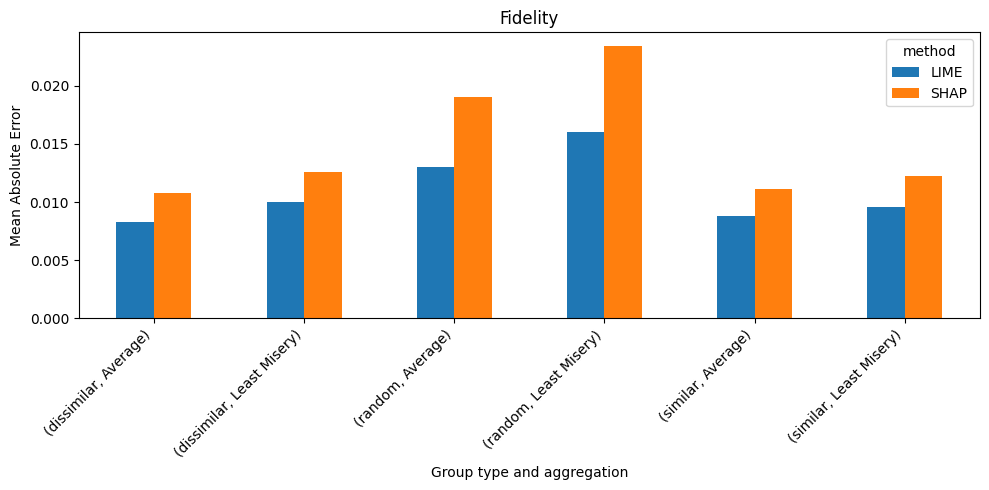

In [93]:
import matplotlib.pyplot as plt

summary = full_group.pivot_table(
    index=["group_type", "aggregation"],
    columns="method",
    values="mae"
)

summary.plot(kind="bar", figsize=(10, 5))

plt.title("Fidelity")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Group type and aggregation")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../results/group_fidelity.png", dpi=300)
plt.show()

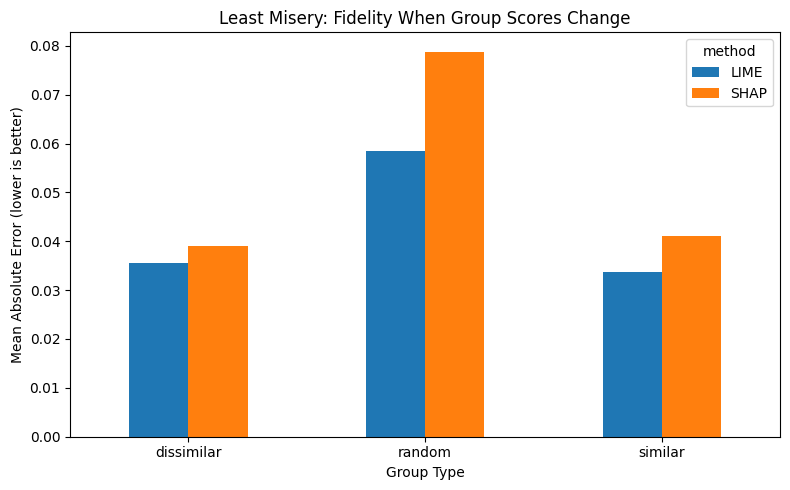

In [94]:
active_summary = full_group[
    full_group["aggregation"] == "Least Misery"
].pivot_table(
    index="group_type",
    columns="method",
    values="active_mae"
)

active_summary.plot(kind="bar", figsize=(8, 5))

plt.title("Least Misery: Fidelity When Group Scores Change")
plt.ylabel("Mean Absolute Error (lower is better)")
plt.xlabel("Group Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/least_misery_active.png", dpi=300)
plt.show()

In [95]:
import shap
import time
from lime.lime_tabular import LimeTabularExplainer
from itertools import product

user_histories = {
    user: history
    for user, history in train.groupby("user_id")
}

In [97]:
print(get_lime_weig)
print(calc_cost)
print(len(user_histories))

<function get_lime_weig at 0x0000020F7BD3B010>
<function calc_cost at 0x0000020F7BD3B370>
943


In [96]:
import numpy as np
import shap
import time

from itertools import product
from lime.lime_tabular import LimeTabularExplainer

user_histories = {user: history
    for user, history in train.groupby("user_id")
}

In [98]:
print(get_lime_weig(556, 313, 42))
print(calc_cost(556, 313))

[ 0.09086041  0.0905292   0.08985725  0.08604124 -0.04527077]
{'lime_time': 0.7253927000565454, 'shap_time': 0.0482692999066785, 'lime_evaluations': 500, 'shap_evaluations': 32}


In [ ]:
from pathlib import Path

cases = pd.read_csv("../results/full_cases.csv")
file = Path("../results/full_stability_cost.csv")
# Check previously saved cases
done = set()

if file.exists():
    saved = pd.read_csv(file)
    done = set(zip(
        saved["group_type"],
        saved["group_id"],
        saved["user_id"],
        saved["movie_id"]
    ))

print("Already completed:", len(done))

# experiment
for case in cases.itertuples(index=False):

    user = int(case.user_id)
    movie = int(case.movie_id)
    key = (case.group_type, case.group_id, user, movie)

    if key in done:
        continue

    # Stability: run LIME five times
    runs = np.array([
        get_lime_weig(user, movie, seed)
        for seed in [42, 43, 44, 45, 46]
    ])

    stability = runs.std(axis=0, ddof=1).mean()

    # Measure computational cost
    cost = calc_cost(user, movie)

    # Save this case
    row = {
        "group_type": case.group_type,
        "group_id": case.group_id,
        "user_id": user,
        "movie_id": movie,
        "lime_stability_sd": stability,
        **cost
    }

    pd.DataFrame([row]).to_csv(
        file, mode="a",
        header=not file.exists(),
        index=False
    )

    done.add(key)

    if len(done) % 20 == 0:
        print(f"Completed {len(done)} / 960", flush=True)

Already completed: 6
Completed 20 / 960
Completed 40 / 960
Completed 60 / 960
Completed 80 / 960
Completed 100 / 960
Completed 120 / 960
Completed 140 / 960
Completed 160 / 960
Completed 180 / 960
Completed 200 / 960
Completed 220 / 960
Completed 240 / 960
Completed 260 / 960
Completed 280 / 960
Completed 300 / 960
Completed 320 / 960
Completed 340 / 960
Completed 360 / 960
Completed 380 / 960
Completed 400 / 960
Completed 420 / 960
Completed 440 / 960
Completed 460 / 960
Completed 480 / 960
Completed 500 / 960
Completed 520 / 960
Completed 540 / 960
Completed 560 / 960
Completed 580 / 960
Completed 600 / 960
Completed 620 / 960
Completed 640 / 960
Completed 660 / 960
Completed 680 / 960
Completed 700 / 960
Completed 720 / 960
Completed 740 / 960
Completed 760 / 960
Completed 780 / 960
Completed 800 / 960
Completed 820 / 960
Completed 840 / 960
Completed 860 / 960
Completed 880 / 960
Completed 900 / 960
Completed 920 / 960
Completed 940 / 960
Completed 960 / 960


In [99]:
results = pd.read_csv("../results/full_stability_cost.csv")

print("Completed cases:", len(results))
print(results.groupby("group_type")[["lime_stability_sd", "lime_time", "shap_time"]].mean().round(4))

Completed cases: 960
            lime_stability_sd  lime_time  shap_time
group_type                                         
dissimilar             0.0019     0.7197     0.0466
random                 0.0036     0.7028     0.0452
similar                0.0020     0.8003     0.0518


In [ ]:

full_cases = pd.read_csv("../results/full_cases.csv")

def show_group_case(group_type, member="lowest"):

    # Pick the first group of this type
    cases = full_cases[full_cases["group_type"] == group_type]
    group = cases[cases["group_id"] == cases.iloc[0]["group_id"]]
    users = group["user_id"].tolist()
    movie = int(group["movie_id"].iloc[0])

    # Get the four original KNN predictions
    predictions = np.array([
        item_predict(user_histories[u], movie)
        for u in users
    ])

    # Choose which group member to change
    if member == "lowest":
        i = np.argmin(predictions)
    else:
        i = np.argmax(predictions)

    user = users[i]
    features = chose_movies(user, movie)

    # Remove the first selected historical rating
    mask = [0, 1, 1, 1, 1]
    actual = pred_masked(user, movie, features, mask)

    # Get LIME's estimated change
    lime_change = get_lime_weig(user, movie, 42)[0]

    # Get SHAP's estimated change
    predictor = create_pred(user, movie, features)
    explainer = shap.Explainer(
        predictor, np.zeros((1, 5)), algorithm="exact"
    )
    shap_change = explainer(np.ones((1, 5))).values[0][0]

    # Compare original, actual, LIME and SHAP predictions
    values = [
        predictions[i],
        actual,
        predictions[i] - lime_change,
        predictions[i] - shap_change
    ]

    rows = []

    for value in values:
        new_preds = predictions.copy()
        new_preds[i] = value

        rows.append([
            value,
            new_preds.mean(),
            new_preds.min()
        ])

    table = pd.DataFrame(
        rows,
        cols=["Member", "Average", "Least Misery"],
        index=["Original", "Actual removal", "LIME", "SHAP"]
    )

    print("Group:", group_type)
    print("Users:", users)
    print("Target movie:", movie)
    print("Affected user:", user)
    print("Removed historical movie:", features[0])
    print()
    print(table.round(4).to_string())


In [39]:
show_group_case("similar", "lowest")

Group: similar
Users: [534, 102, 84, 907]
Target movie: 521
Affected user: 102
Removed historical movie: 13

                Member  Average  Least Misery
Original        2.8531   3.8722        2.8531
Actual removal  2.8491   3.8712        2.8491
LIME            2.8573   3.8732        2.8573
SHAP            2.8569   3.8731        2.8569


In [ ]:
show_group_case("dissimilar", "highest")